In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from hmmlearn.hmm import CategoricalHMM
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    balanced_accuracy_score,
    accuracy_score,
)
import joblib
from pathlib import Path

In [2]:
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

data_path = (
    project_root
    / "data"
    / "processed"
    / "sicorello_modeling_df.parquet"
)

df = pd.read_parquet(data_path)

In [3]:
# Sort chronologically within each participant
df = df.sort_values(
    ["id", "day", "beep"]
).reset_index(drop=True)

# Validate required columns
required_cols = {"id", "day", "beep", "response"}
assert required_cols.issubset(df.columns)
assert df["response"].isin([0, 1]).all()
assert not df.duplicated(["id", "day", "beep"]).any()

X = df[["response"]].to_numpy(dtype=int)

# Each participant is a separate sequence.
# The lengths list tells hmmlearn where each sequence ends.
lengths = (
    df.groupby("id", sort=False)
    .size()
    .tolist()
)

assert sum(lengths) == len(X)

print(f"Participants: {df['id'].nunique():,}")
print(f"Observations: {len(X):,}")
print(f"Sequence lengths: {len(lengths):,}")
print(f"Overall nonresponse rate: {1 - df['response'].mean():.3f}")

Participants: 222
Observations: 13,320
Sequence lengths: 222
Overall nonresponse rate: 0.353


# Experiment 4

# Experiment 1

In [4]:
def fit_best_hmm(
    X,
    lengths,
    n_states,
    seeds=range(10),
    n_iter=300,
    tol=1e-4,
):
    best_model = None
    best_log_likelihood = -np.inf

    for seed in seeds:
        model = CategoricalHMM(
            n_components=n_states,
            n_features=2,
            n_iter=n_iter,
            tol=tol,
            random_state=seed,
            implementation="log",
        )

        model.fit(X, lengths)

        log_likelihood = model.score(X, lengths)

        if np.isfinite(log_likelihood) and (
            log_likelihood > best_log_likelihood
        ):
            best_model = model
            best_log_likelihood = log_likelihood

    if best_model is None:
        raise RuntimeError(
            f"No successful fit for {n_states}-state HMM."
        )

    return best_model, best_log_likelihood


# Fit both contestants
hmm_2, ll_2 = fit_best_hmm(
    X, lengths, n_states=2
)

hmm_3, ll_3 = fit_best_hmm(
    X, lengths, n_states=3
)

print("2-state HMM log-likelihood:", ll_2)
print("3-state HMM log-likelihood:", ll_3)

2-state HMM log-likelihood: -6638.607322378605
3-state HMM log-likelihood: -6249.2124673962035


In [5]:
def summarize_hmm(model, n_states):
    print(f"\n{'=' * 45}")
    print(f"{n_states}-STATE HMM")
    print(f"{'=' * 45}")

    print("\nInitial state probabilities:")
    print(np.round(model.startprob_, 4))

    print("\nTransition probabilities:")
    print(pd.DataFrame(
        model.transmat_,
        index=[f"State {i}" for i in range(n_states)],
        columns=[f"State {i}" for i in range(n_states)],
    ).round(4))

    print("\nEmission probabilities:")
    emission_df = pd.DataFrame(
        model.emissionprob_,
        index=[f"State {i}" for i in range(n_states)],
        columns=["P(response=0)", "P(response=1)"],
    )
    print(emission_df.round(4))

    return emission_df


emissions_2 = summarize_hmm(hmm_2, 2)
emissions_3 = summarize_hmm(hmm_3, 3)


2-STATE HMM

Initial state probabilities:
[0. 1.]

Transition probabilities:
         State 0  State 1
State 0   0.7299   0.2701
State 1   0.1549   0.8451

Emission probabilities:
         P(response=0)  P(response=1)
State 0         1.0000         0.0000
State 1         0.0198         0.9802

3-STATE HMM

Initial state probabilities:
[1. 0. 0.]

Transition probabilities:
         State 0  State 1  State 2
State 0   0.8305   0.0082   0.1613
State 1   0.0000   1.0000   0.0000
State 2   0.4309   0.0001   0.5689

Emission probabilities:
         P(response=0)  P(response=1)
State 0         0.0000         1.0000
State 1         0.9812         0.0188
State 2         1.0000         0.0000


In [6]:
comparison = pd.DataFrame({
    "model": ["2-state HMM", "3-state HMM"],
    "n_states": [2, 3],
    "train_log_likelihood": [ll_2, ll_3],
    "log_likelihood_per_prompt": [
        ll_2 / len(X),
        ll_3 / len(X),
    ],
})

display(comparison)

,model,n_states,train_log_likelihood,log_likelihood_per_prompt
0,2-state HMM,2,-6638.607322,-0.498394
1,3-state HMM,3,-6249.212467,-0.469160


In [7]:
df["state_2"] = hmm_2.predict(X, lengths=lengths)
df["state_3"] = hmm_3.predict(X, lengths=lengths)

def state_summary(df, state_col):
    summary = (
        df.groupby(state_col)
        .agg(
            prompts=("response", "size"),
            nonresponse_rate=("response", lambda s: 1 - s.mean()),
            response_rate=("response", "mean"),
            participants=("id", "nunique"),
        )
        .sort_values("nonresponse_rate", ascending=False)
    )

    return summary


print("2-state model:")
display(state_summary(df, "state_2"))

print("3-state model:")
display(state_summary(df, "state_3"))

2-state model:


,prompts,nonresponse_rate,response_rate,participants
state_2,,,,
0,4699,1.0,0.0,222
1,8621,0.0,1.0,222


3-state model:


,prompts,nonresponse_rate,response_rate,participants
state_3,,,,
2,3056,1.000000,0.000000,213
1,1669,0.984422,0.015578,61
0,8595,0.000000,1.000000,222


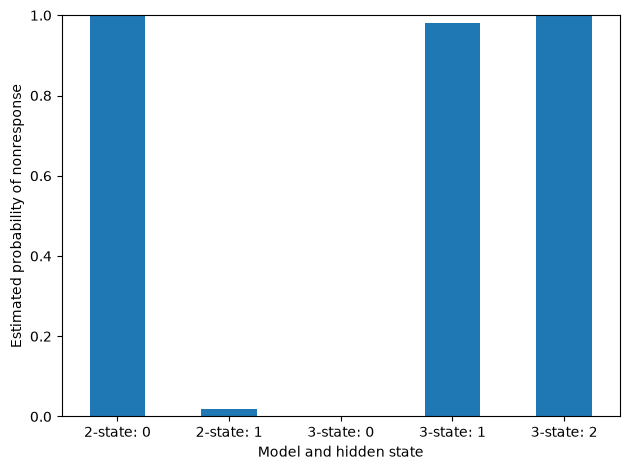

In [8]:
emission_plot = pd.DataFrame({
    "State": (
        [f"2-state: {i}" for i in range(2)]
        + [f"3-state: {i}" for i in range(3)]
    ),
    "P(nonresponse)": (
        list(hmm_2.emissionprob_[:, 0])
        + list(hmm_3.emissionprob_[:, 0])
    ),
})

ax = emission_plot.plot(
    x="State",
    y="P(nonresponse)",
    kind="bar",
    legend=False,
    rot=0,
)

ax.set_ylabel("Estimated probability of nonresponse")
ax.set_xlabel("Model and hidden state")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

In [9]:
# model_dir = project_root / "models" / "sicorello"
# model_dir.mkdir(parents=True, exist_ok=True)

# joblib.dump(hmm_2, model_dir / "categorical_hmm_2state.joblib")
# joblib.dump(hmm_3, model_dir / "categorical_hmm_3state.joblib")

# df.to_parquet(
#     project_root / "data" / "processed"
#     / "sicorello_hmm_states_exploratory.parquet",
#     index=False,
# )

# comparison.to_csv(
#     model_dir / "training_comparison.csv",
#     index=False,
# )

# print(f"Saved models and outputs to: {model_dir.resolve()}")

In [10]:
print("Rows in df:", len(df))
print("Rows in X:", len(X))
print("Total sequence lengths:", sum(lengths))
print("Unique participants:", df["id"].nunique())

Rows in df: 13320
Rows in X: 13320
Total sequence lengths: 13320
Unique participants: 222


# Experiment 2

In [12]:
train_df = df[df["day"] <= 6].copy()
test_df = df[df["day"] >= 7].copy()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))
print("Participants:", df["id"].nunique())

print("\nTraining days:", sorted(train_df["day"].unique()))
print("Testing days:", sorted(test_df["day"].unique()))

print("\nRows per participant in training:")
print(train_df.groupby("id").size().value_counts().sort_index())

print("\nRows per participant in testing:")
print(test_df.groupby("id").size().value_counts().sort_index())

Training rows: 7992
Testing rows: 5328
Participants: 222

Training days: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Testing days: [np.int64(7), np.int64(8), np.int64(9), np.int64(10)]

Rows per participant in training:
36    222
Name: count, dtype: int64

Rows per participant in testing:
24    222
Name: count, dtype: int64


In [13]:
def fit_best_hmm(X, lengths, n_states, seeds=range(10)):
    best_model = None
    best_score = -np.inf

    for seed in seeds:
        model = CategoricalHMM(
            n_components=n_states,
            n_features=2,
            n_iter=300,
            tol=1e-4,
            random_state=seed,
            implementation="log",
            startprob_prior=1.1,
            transmat_prior=1.1,
            emissionprob_prior=1.1,
        )

        model.fit(X, lengths)
        score = model.score(X, lengths)

        if np.isfinite(score) and score > best_score:
            best_model = model
            best_score = score

    if best_model is None:
        raise RuntimeError(
            f"No successful fit for {n_states}-state HMM."
        )

    return best_model, best_score


# Keep participants' training sequences separate.
train_df = train_df.sort_values(
    ["id", "day", "beep"]
).reset_index(drop=True)

X_train = train_df[["response"]].to_numpy(dtype=int)

train_lengths = (
    train_df.groupby("id", sort=False)
    .size()
    .tolist()
)

hmm_2, hmm_2_train_ll = fit_best_hmm(
    X_train, train_lengths, n_states=2
)

hmm_3, hmm_3_train_ll = fit_best_hmm(
    X_train, train_lengths, n_states=3
)

print("2-state training log-likelihood:", hmm_2_train_ll)
print("3-state training log-likelihood:", hmm_3_train_ll)

print("\n2-state emission probabilities:")
print(hmm_2.emissionprob_)

print("\n3-state emission probabilities:")
print(hmm_3.emissionprob_)

2-state training log-likelihood: -3865.1783477477807
3-state training log-likelihood: -3768.5684801737984

2-state emission probabilities:
[[9.99711104e-01 2.88895946e-04]
 [5.02006917e-04 9.99497993e-01]]

3-state emission probabilities:
[[8.11321106e-02 9.18867889e-01]
 [9.99753385e-01 2.46615212e-04]
 [1.93505634e-04 9.99806494e-01]]


In [14]:
def predict_hmm_sequence(model, observed_responses):
    """
    Produce one-step-ahead probabilities for a single participant.

    Each prediction uses the preceding observations only.
    The first observation initializes the filtered state distribution.
    """
    observations = np.asarray(observed_responses, dtype=int)

    startprob = np.asarray(model.startprob_, dtype=float)
    transmat = np.asarray(model.transmat_, dtype=float)
    emission = np.asarray(model.emissionprob_, dtype=float)

    # Numerical safeguards for probability calculations.
    startprob = np.maximum(startprob, 1e-12)
    startprob = startprob / startprob.sum()

    transmat = np.maximum(transmat, 1e-12)
    transmat = transmat / transmat.sum(axis=1, keepdims=True)

    emission = np.maximum(emission, 1e-12)
    emission = emission / emission.sum(axis=1, keepdims=True)

    # Filter using the training observations.
    alpha = startprob * emission[:, observations[0]]
    alpha = alpha / alpha.sum()

    # One-step-ahead probabilities for subsequent observations.
    predictions = []

    for observed in observations[1:]:
        predicted_state = alpha @ transmat

        p_nonresponse = predicted_state @ emission[:, 0]
        predictions.append(p_nonresponse)

        # Update the filtered state distribution after the outcome arrives.
        alpha = predicted_state * emission[:, observed]
        alpha = alpha / alpha.sum()

    return np.asarray(predictions)


def evaluate_hmm(model, train_df, test_df):
    predictions = []

    for participant_id, test_group in test_df.groupby("id", sort=False):
        participant_train = (
            train_df[train_df["id"] == participant_id]
            .sort_values(["day", "beep"])
        )

        test_group = test_group.sort_values(["day", "beep"])

        train_responses = participant_train["response"].to_numpy(dtype=int)
        test_responses = test_group["response"].to_numpy(dtype=int)

        full_sequence = np.concatenate([
            train_responses,
            test_responses,
        ])

        # Predict the entire sequence one step ahead, then retain
        # only predictions corresponding to the test period.
        full_predictions = predict_hmm_sequence(
            model, full_sequence
        )

        test_predictions = full_predictions[len(train_responses) - 1:]

        predictions.append(pd.DataFrame({
            "id": participant_id,
            "day": test_group["day"].to_numpy(),
            "beep": test_group["beep"].to_numpy(),
            "response": test_responses,
            "p_nonresponse": test_predictions,
            "model": f"{model.n_components}-state HMM",
        }))

    return pd.concat(predictions, ignore_index=True)


pred_hmm_2 = evaluate_hmm(hmm_2, train_df, test_df)
pred_hmm_3 = evaluate_hmm(hmm_3, train_df, test_df)

print(pred_hmm_2.head())

           id  day  beep  response  p_nonresponse        model
0  s003987858    7     1         1       0.163402  2-state HMM
1  s003987858    7     2         1       0.163402  2-state HMM
2  s003987858    7     3         1       0.163402  2-state HMM
3  s003987858    7     4         1       0.163402  2-state HMM
4  s003987858    7     5         1       0.163402  2-state HMM


In [15]:
# --------------------------------------------------
# Baseline 1: previous-response transition model
# --------------------------------------------------

transition_train = train_df.dropna(
    subset=["prev_response"]
).copy()

transition_train["prev_response"] = (
    transition_train["prev_response"].astype(int)
)

# Estimate P(response=1 | previous response), with Laplace smoothing.
transition_counts = pd.crosstab(
    transition_train["prev_response"],
    transition_train["response"],
).reindex(index=[0, 1], columns=[0, 1], fill_value=0)

p_response_given_prev = (
    (transition_counts[1] + 1)
    / (transition_counts.sum(axis=1) + 2)
)

baseline_df = test_df[
    ["id", "day", "beep", "response", "prev_response"]
].copy()

baseline_df["p_nonresponse"] = (
    1 - baseline_df["prev_response"].astype(int).map(
        p_response_given_prev
    )
).astype(float)

baseline_df["model"] = "Previous-response baseline"


# --------------------------------------------------
# Baseline 2: logistic regression
# --------------------------------------------------

feature_cols = [
    "day",
    "beep",
    "prompt_index",
    "prev_response",
    "prev_response_same_day",
    "prior_cumulative_response_rate",
    "prior_3_prompt_response_rate",
    "prior_day_response_rate",
]

logistic_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42),
)

logistic_model.fit(
    train_df[feature_cols],
    train_df["response"],
)

p_response_logistic = logistic_model.predict_proba(
    test_df[feature_cols]
)[:, 1]

logistic_df = test_df[
    ["id", "day", "beep", "response"]
].copy()

logistic_df["p_nonresponse"] = 1 - p_response_logistic
logistic_df["model"] = "Logistic regression"

In [16]:
def evaluate_predictions(prediction_df):
    y_true = 1 - prediction_df["response"].to_numpy(dtype=int)
    p = prediction_df["p_nonresponse"].to_numpy(dtype=float)

    # Avoid numerical problems in log loss.
    p = np.clip(p, 1e-7, 1 - 1e-7)

    return {
        "n_test_prompts": len(y_true),
        "test_nonresponse_rate": y_true.mean(),
        "ROC_AUC": roc_auc_score(y_true, p),
        "PR_AUC": average_precision_score(y_true, p),
        "log_loss": log_loss(y_true, np.column_stack([1 - p, p])),
        "Brier_score": brier_score_loss(y_true, p),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, (p >= 0.5).astype(int)
        ),
        "accuracy": accuracy_score(
            y_true, (p >= 0.5).astype(int)
        ),
    }


predictions = pd.concat(
    [
        baseline_df[
            ["id", "day", "beep", "response", "p_nonresponse", "model"]
        ],
        logistic_df[
            ["id", "day", "beep", "response", "p_nonresponse", "model"]
        ],
        pred_hmm_2,
        pred_hmm_3,
    ],
    ignore_index=True,
)

results = pd.DataFrame({
    name: evaluate_predictions(group)
    for name, group in predictions.groupby("model", sort=False)
}).T

results = results.sort_values("log_loss")

display(results.round(4))

,n_test_prompts,test_nonresponse_rate,ROC_AUC,PR_AUC,log_loss,Brier_score,balanced_accuracy,accuracy
Logistic regression,5328.0,0.4185,0.9523,0.9477,0.2688,0.0869,0.8469,0.8696
3-state HMM,5328.0,0.4185,0.8393,0.8331,0.4979,0.1601,0.7813,0.7920
2-state HMM,5328.0,0.4185,0.7977,0.8063,0.5235,0.1701,0.7771,0.7834
Previous-response baseline,5328.0,0.4185,0.7771,0.6579,0.5235,0.1702,0.7771,0.7834


In [17]:
# model_dir = project_root / "models" / "sicorello"
# model_dir.mkdir(parents=True, exist_ok=True)

# results.to_csv(model_dir / "test_metrics.csv")

# predictions.to_parquet(
#     project_root / "data" / "processed"
#     / "sicorello_test_predictions.parquet",
#     index=False,
# )

# joblib.dump(
#     hmm_2,
#     model_dir / "categorical_hmm_2state_train_days1_6.joblib",
# )

# joblib.dump(
#     hmm_3,
#     model_dir / "categorical_hmm_3state_train_days1_6.joblib",
# )

# joblib.dump(
#     logistic_model,
#     model_dir / "logistic_baseline_train_days1_6.joblib",
# )

# print(f"Results saved to {model_dir.resolve()}")

# Experiment 3

In [18]:
train_df = train_df.sort_values(["id", "day", "beep"]).copy()
test_df = test_df.sort_values(["id", "day", "beep"]).copy()

X_train = train_df["response"].to_numpy(dtype=int).reshape(-1, 1)
lengths_train = (
    train_df.groupby("id", sort=False)
    .size()
    .tolist()
)

In [24]:
hmm_4_result = fit_best_hmm(
    X=X_train,
    lengths=lengths_train,
    n_states=4,
    seeds=range(10),
)

print("Type:", type(hmm_4_result))
print("Contents:", hmm_4_result)

if isinstance(hmm_4_result, tuple):
    for i, item in enumerate(hmm_4_result):
        print(f"Element {i}: type={type(item)}, value={item if isinstance(item, (int, float, str)) else repr(item)[:300]}")

Model is not converging.  Current: -3679.1108154317744 is not greater than -3679.1106825883912. Delta is -0.0001328433831986331


Type: <class 'tuple'>
Contents: (CategoricalHMM(emissionprob_prior=1.1, n_components=4, n_features=2, n_iter=300,
               random_state=RandomState(MT19937) at 0x2714C12B240,
               startprob_prior=1.1, tol=0.0001, transmat_prior=1.1), -3622.7187732790153)
Element 0: type=<class 'hmmlearn.hmm.CategoricalHMM'>, value=CategoricalHMM(emissionprob_prior=1.1, n_components=4, n_features=2, n_iter=300,
               random_state=RandomState(MT19937) at 0x2714C12B240,
               startprob_prior=1.1, tol=0.0001, transmat_prior=1.1)
Element 1: type=<class 'float'>, value=-3622.7187732790153


In [25]:
hmm_4, hmm_4_loglik = fit_best_hmm(
    X=X_train,
    lengths=lengths_train,
    n_states=4,
    seeds=range(10),
)

print("4-state HMM fitted.")
print("Training log-likelihood:", hmm_4_loglik)

print("\nInitial state probabilities:")
print(np.round(hmm_4.startprob_, 4))

print("\nTransition matrix:")
print(np.round(hmm_4.transmat_, 4))

print("\nEmission probabilities:")
print(np.round(hmm_4.emissionprob_, 4))

Model is not converging.  Current: -3679.1108154317744 is not greater than -3679.1106825883912. Delta is -0.0001328433831986331


4-state HMM fitted.
Training log-likelihood: -3622.7187732790153

Initial state probabilities:
[4.000e-04 5.000e-04 3.700e-03 9.954e-01]

Transition matrix:
[[5.291e-01 1.200e-03 5.000e-04 4.693e-01]
 [4.420e-02 9.546e-01 4.000e-04 8.000e-04]
 [1.951e-01 4.000e-04 7.958e-01 8.800e-03]
 [2.000e-04 5.700e-02 5.436e-01 3.992e-01]]

Emission probabilities:
[[9.996e-01 4.000e-04]
 [9.282e-01 7.180e-02]
 [1.000e-04 9.999e-01]
 [1.000e-04 9.999e-01]]


In [26]:
pred_hmm_4 = evaluate_hmm(hmm_4, train_df, test_df)
pred_hmm_4["model"] = "4-state HMM"

predictions = predictions[
    predictions["model"] != "4-state HMM"
].copy()

predictions = pd.concat(
    [predictions, pred_hmm_4],
    ignore_index=True,
)

results = (
    predictions.groupby("model")
    .apply(calculate_metrics, include_groups=False)
    .sort_values("log_loss")
)

display(results.round(4))

,n_test_prompts,test_nonresponse_rate,ROC_AUC,PR_AUC,log_loss,Brier_score,balanced_accuracy,accuracy
model,,,,,,,,
Logistic regression,5328.0,0.4185,0.9523,0.9477,0.2688,0.0869,0.8469,0.8696
4-state HMM,5328.0,0.4185,0.8400,0.8224,0.4617,0.1488,0.7768,0.7821
3-state HMM,5328.0,0.4185,0.8393,0.8331,0.4979,0.1601,0.7813,0.7920
2-state HMM,5328.0,0.4185,0.7977,0.8063,0.5235,0.1701,0.7771,0.7834
Previous-response baseline,5328.0,0.4185,0.7771,0.6579,0.5235,0.1702,0.7771,0.7834


# Verifying Features